# Aula Prática: Classificação com Naive Bayes 🧠

Este notebook apresenta o passo a passo para a construção e avaliação de um modelo de Machine Learning utilizando o algoritmo **Naive Bayes**. Você aprenderá a carregar dados reais de seguros, preparar os dados transformando variáveis textuais em números, treinar o classificador e avaliar o seu desempenho por meio de métricas de validação e de uma Matriz de Confusão.

### 🎯 Objetivos de Aprendizagem
Ao final desta aula, você será capaz de:
1. Compreender o funcionamento prático do algoritmo Naive Bayes para problemas de classificação multi-classe.
2. Realizar o pré-processamento de dados categóricos utilizando a técnica de codificação de etiquetas (*Label Encoding*).
3. Dividir um conjunto de dados entre treino e teste para validar modelos de forma justa.
4. Interpretar métricas de desempenho como Acurácia, Precisão, Recall, F1-Score e a Matriz de Confusão.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from yellowbrick.classifier import ConfusionMatrix

## 1. Importação das Ferramentas (Bibliotecas)

Antes de começarmos a trabalhar com dados, precisamos trazer para o nosso ambiente as ferramentas necessárias. Em Python, fazemos isso importando **bibliotecas**:
* **`pandas` (pd):** Essencial para manipulação e análise de dados em formato de tabelas (DataFrames).
* **`numpy` (np):** Biblioteca para operações matemáticas e manipulação de arrays (vetores/matrizes).
* **`sklearn` (scikit-learn):** A principal biblioteca de Machine Learning do Python, de onde importamos o nosso modelo (`GaussianNB`), funções para divisão de dados (`train_test_split`), codificação de categorias (`LabelEncoder`) e métricas de avaliação.
* **`yellowbrick`:** Uma ferramenta de visualização para Machine Learning que nos ajudará a analisar visualmente a performance do modelo através da Matriz de Confusão.

In [2]:
base = pd.read_csv("insurance.csv", keep_default_na=False)
base.head()

,Unnamed: 0,GoodStudent,Age,SocioEcon,RiskAversion,VehicleYear,ThisCarDam,RuggedAuto,Accident,MakeModel,...,HomeBase,AntiTheft,PropCost,OtherCarCost,OtherCar,MedCost,Cushioning,Airbag,ILiCost,DrivHist
0,1,False,Adult,Prole,Adventurous,Older,Moderate,EggShell,Mild,Economy,...,City,False,TenThou,Thousand,True,Thousand,Poor,False,Thousand,Many
1,2,False,Senior,Prole,Cautious,Current,None,Football,None,Economy,...,City,True,Thousand,Thousand,True,Thousand,Good,True,Thousand,Zero
2,3,False,Senior,UpperMiddle,Psychopath,Current,None,Football,None,FamilySedan,...,City,False,Thousand,Thousand,False,Thousand,Good,True,Thousand,One
3,4,False,Adolescent,Middle,Normal,Older,None,EggShell,None,Economy,...,Suburb,False,Thousand,Thousand,True,Thousand,Fair,False,Thousand,Zero
4,5,False,Adolescent,Prole,Normal,Older,Moderate,Football,Moderate,Economy,...,City,False,TenThou,Thousand,False,Thousand,Fair,False,Thousand,Many


## 2. Carga dos Dados

Aqui carregamos o arquivo `insurance.csv` usando a função `read_csv` do Pandas. O argumento `keep_default_na=False` é usado para garantir que campos que possam parecer nulos por padrão (como a string 'NA') sejam tratados literalmente como texto, e não como valores faltantes.

O método `.head()` exibe as 5 primeiras linhas para entendermos a estrutura das colunas (atributos) que temos disponível.

In [3]:
base = base.drop(columns=['Unnamed: 0'])
base.head()

,GoodStudent,Age,SocioEcon,RiskAversion,VehicleYear,ThisCarDam,RuggedAuto,Accident,MakeModel,DrivQuality,...,HomeBase,AntiTheft,PropCost,OtherCarCost,OtherCar,MedCost,Cushioning,Airbag,ILiCost,DrivHist
0,False,Adult,Prole,Adventurous,Older,Moderate,EggShell,Mild,Economy,Poor,...,City,False,TenThou,Thousand,True,Thousand,Poor,False,Thousand,Many
1,False,Senior,Prole,Cautious,Current,None,Football,None,Economy,Normal,...,City,True,Thousand,Thousand,True,Thousand,Good,True,Thousand,Zero
2,False,Senior,UpperMiddle,Psychopath,Current,None,Football,None,FamilySedan,Excellent,...,City,False,Thousand,Thousand,False,Thousand,Good,True,Thousand,One
3,False,Adolescent,Middle,Normal,Older,None,EggShell,None,Economy,Normal,...,Suburb,False,Thousand,Thousand,True,Thousand,Fair,False,Thousand,Zero
4,False,Adolescent,Prole,Normal,Older,Moderate,Football,Moderate,Economy,Poor,...,City,False,TenThou,Thousand,False,Thousand,Fair,False,Thousand,Many


## 3. Limpeza dos Dados

A primeira coluna do nosso arquivo (`Unnamed: 0`) continha apenas um índice sequencial sem valor informativo para o algoritmo de aprendizado. Nós a removemos usando o método `.drop()` para manter apenas características que de fato ajudem o modelo a prever o risco do seguro.

In [4]:
base.shape

(20000, 27)

In [5]:
print(base.isnull().sum())

GoodStudent     0
Age             0
SocioEcon       0
RiskAversion    0
VehicleYear     0
ThisCarDam      0
RuggedAuto      0
Accident        0
MakeModel       0
DrivQuality     0
Mileage         0
Antilock        0
DrivingSkill    0
SeniorTrain     0
ThisCarCost     0
Theft           0
CarValue        0
HomeBase        0
AntiTheft       0
PropCost        0
OtherCarCost    0
OtherCar        0
MedCost         0
Cushioning      0
Airbag          0
ILiCost         0
DrivHist        0
dtype: int64


## 4. Separação de Previsores (X) e Classe Alvo (y)

Para que o modelo aprenda, precisamos separar nossos dados em duas partes:
1. **Atributos Previsores ($X$):** As características que descrevem o cliente e o carro (ex: idade, comportamento, ano do veículo).
2. **Classe Alvo ($y$):** O que queremos prever. Neste caso, o nível de sinistro/acidente (`Accident` - localizado na coluna de índice 7).

💡 *Para pensar:* No código, usamos `y = base.iloc[:,7].values` para pegar a coluna de índice 7 de forma estática. Se a ordem das colunas no arquivo CSV mudar, isso pode quebrar o código ou selecionar a coluna errada. Uma alternativa mais robusta seria buscar a coluna pelo nome: `y = base['Accident'].values`.

In [8]:
y = base.iloc[:,7].values
X = base.drop(base.columns[7], axis=1).values
X

array([[False, 'Adult', 'Prole', ..., False, 'Thousand', 'Many'],
       [False, 'Senior', 'Prole', ..., True, 'Thousand', 'Zero'],
       [False, 'Senior', 'UpperMiddle', ..., True, 'Thousand', 'One'],
       ...,
       [False, 'Senior', 'UpperMiddle', ..., True, 'Thousand', 'Zero'],
       [False, 'Adult', 'Middle', ..., True, 'Thousand', 'Zero'],
       [False, 'Adult', 'Middle', ..., True, 'Thousand', 'Zero']],
      shape=(20000, 26), dtype=object)

In [9]:
labelencoder = LabelEncoder()
for i in range(X.shape[1]):
  if X[:,i].dtype == 'object':
    X[:,i] = labelencoder.fit_transform(X[:,i])

## 5. Codificação de Variáveis Categóricas (*Label Encoding*)

O algoritmo Naive Bayes trabalha calculando probabilidades baseadas em números. No entanto, muitas colunas do nosso conjunto de dados contêm categorias textuais (como "Adult", "Senior", "Prole").

Para resolver isso, utilizamos o **`LabelEncoder`**. Ele funciona como um dicionário que atribui um número exclusivo para cada categoria textual existente em cada coluna (ex: "Adult" vira 0, "Senior" vira 1, etc.). O laço `for` percorre cada coluna de nossos atributos previsores ($X$) que seja do tipo textual (`object`) e faz essa conversão automaticamente.

In [10]:
X

array([[0, 1, 1, ..., 0, 3, 0],
       [0, 2, 1, ..., 1, 3, 2],
       [0, 2, 2, ..., 1, 3, 1],
       ...,
       [0, 2, 2, ..., 1, 3, 2],
       [0, 1, 0, ..., 1, 3, 2],
       [0, 1, 0, ..., 1, 3, 2]], shape=(20000, 26), dtype=object)

In [19]:
X_treinamento, X_teste, y_treinamento, y_teste = train_test_split(X,y,test_size=0.3, random_state=12)

## 6. Divisão entre Treino e Teste

Para avaliar se o modelo realmente aprendeu a generalizar (e não apenas decorou as respostas), nós dividimos os dados em duas partes:
* **Dados de Treinamento (70%):** Usados para o algoritmo aprender os padrões de probabilidade.
* **Dados de Teste (30%):** Dados guardados em segredo que usaremos para testar o modelo após o treinamento.

O `random_state=12` serve como uma "semente" para garantir que a divisão seja feita da mesma forma toda vez que rodarmos o código, permitindo a reprodutibilidade dos resultados.

In [12]:
modelo = GaussianNB()
modelo.fit(X_treinamento,y_treinamento)

GaussianNB()

## 7. Treinamento do Modelo

Aqui instanciamos o **GaussianNB** (que assume que a distribuição das variáveis numéricas contínuas segue uma curva Gaussiana/normal) e usamos o método `.fit(X_treinamento, y_treinamento)` para que ele calcule as probabilidades associadas a cada atributo em relação a nossa classe alvo.

In [18]:
previsoes = modelo.predict(X_teste)

In [14]:
previsoes

array(['Moderate', 'Mild', 'Moderate', ..., 'None', 'Mild', 'None'],
      shape=(6000,), dtype='<U8')

In [15]:
accuracy = accuracy_score(y_teste,previsoes)
precision = precision_score(y_teste, previsoes, average='weighted')
recall = recall_score(y_teste, previsoes, average='weighted')
f1 = f1_score(y_teste, previsoes, average='weighted')
print(f'Acurácia: {accuracy}, Precisão: {precision}, Recall: {recall}, F1: {f1}')

Acurácia: 0.857, Precisão: 0.919107010136158, Recall: 0.857, F1: 0.8343753099843555


## 8. Avaliação do Modelo

Após o modelo fazer as previsões para o grupo de teste, comparamos o que ele previu (`previsoes`) com o que realmente aconteceu (`y_teste`). As métricas utilizadas são:
* **Acurácia:** Proporção geral de acertos do modelo.
* **Precisão:** Dentre as classificações que o modelo disse ser da classe X, quantas de fato eram corretas.
* **Recall (Sensibilidade):** Dentre todos os casos que eram realmente da classe X, quantos o modelo conseguiu identificar.
* **F1-Score:** Uma média harmônica entre a Precisão e o Recall, ótima para avaliar o modelo de forma equilibrada.

In [16]:
report = classification_report(y_teste, previsoes)
print(report)

              precision    recall  f1-score   support

        Mild       0.89      0.70      0.79       570
    Moderate       0.38      0.91      0.54       488
        None       0.98      1.00      0.99      4253
      Severe       0.96      0.07      0.13       689

    accuracy                           0.86      6000
   macro avg       0.80      0.67      0.61      6000
weighted avg       0.92      0.86      0.83      6000



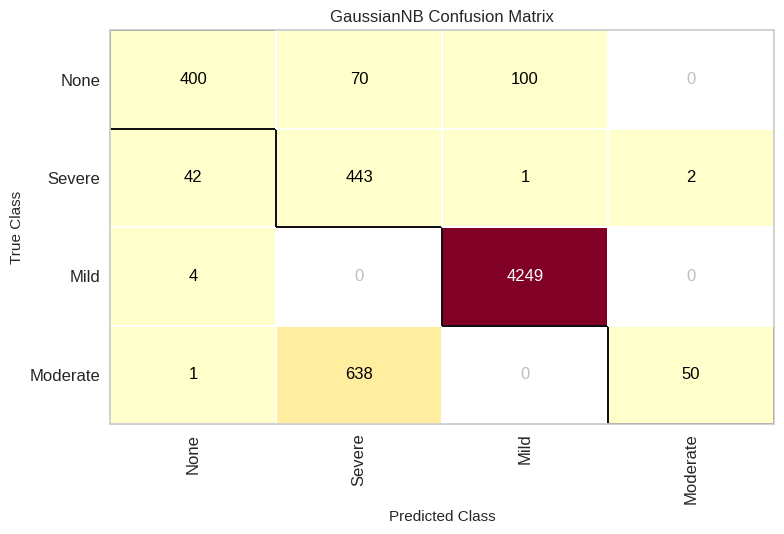

<Axes: title={'center': 'GaussianNB Confusion Matrix'}, xlabel='Predicted Class', ylabel='True Class'>

In [21]:
confusion = ConfusionMatrix(modelo, classes=['None','Severe','Mild','Moderate'])
confusion.fit(X_treinamento, y_treinamento)
confusion.score(X_teste, y_teste)
confusion.poof()

## 📌 Resumo Final, Erros Comuns e Exercícios

### ⚠️ Erros Comuns ao trabalhar com Naive Bayes:
1. **Ignorar dados nulos:** O Naive Bayes do scikit-learn não lida com valores faltantes diretamente. Certifique-se sempre de limpá-los antes (como fizemos usando o `.isnull().sum()`).
2. **Tentar rodar sem codificar:** Tentar treinar o modelo mantendo variáveis textuais diretamente na matriz $X$ gerará um erro. A conversão com `LabelEncoder` ou `OneHotEncoder` é obrigatória.
3. **Classes Desbalanceadas:** Note no relatório de classificação que a classe `Severe` tem pouquíssimos exemplos comparada à classe `None` (suporte de 689 vs 4253). Isso fez com que o Recall de `Severe` ficasse muito baixo (0.07). O modelo tendeu a classificar a maioria dos casos raros como a classe majoritária.

---

### 📝 Exercícios Propostos

1. **Fácil:** Altere a proporção de divisão de treino e teste para 80% de treinamento e 20% de teste (`test_size=0.2`) e verifique se as métricas de acurácia sofrem alguma alteração significativa.
2. **Médio:** Crie uma célula de texto explicando o motivo do modelo ter alcançado um f1-score tão baixo (0.13) na classe `Severe`, correlacionando com a quantidade de dados disponíveis (suporte) exibidos no `classification_report`.
3. **Desafiador:** O `LabelEncoder` atribui pesos arbitrários ordenados (0, 1, 2...). Pesquise sobre o **`OneHotEncoder`** (codificação dummy), aplique-o na matriz $X$ e analise se o desempenho do classificador `GaussianNB` melhora ou piora comparado ao método atual.

---

### 🚀 Para ir além
* **Teorema de Bayes:** Entenda a matemática por trás da probabilidade condicional ($P(A|B) = \frac{P(B|A) \cdot P(A)}{P(B)}$).
* **Variantes do Naive Bayes:** Pesquise sobre o `MultinomialNB` (muito usado para classificação de textos e contagem de palavras) e `BernoulliNB` (para atributos binários/booleanos).